# Hybrid attention in DeepSeek-V4: Compressed Sparse Attention and Heavily Compressed Attention
### Notebook 1 of 9 on DeepSeek-V4 (technical report, [arXiv:2606.19348](https://arxiv.org/abs/2606.19348), §2.3)

At one million tokens of context, attention stops being one cost among several and becomes the cost: every generated token has to read a key-value (KV) cache that grows with the context, and has to compute scores against it. DeepSeek-V4 attacks both with two attention layers that are **interleaved** through the network: Compressed Sparse Attention (CSA) and Heavily Compressed Attention (HCA).

**Headline numbers from the report** (V4-Pro vs DeepSeek-V3.2 at a 1M-token context, Fig. 1): **3.7× lower single-token inference FLOPs (27 %)** and **9.5× smaller KV cache (≈10 %)**; V4-Flash reaches 9.8× and 13.7×. Against a plain BF16 grouped-query-attention (GQA, 8 KV heads, head dimension 128) baseline the report puts the V4 KV cache at "approximately 2 %". We did not rerun the model.

**What this notebook does.** We implement every equation in §2.3 in PyTorch at toy size, check each one (causality, relative-position behaviour, equivalence to a loop reference), and reproduce the headline cache ratio from the paper's own configuration. Everything marked *paper* is quoted; everything marked *we computed* is arithmetic or code in this notebook. Where the report defers to its open-source implementation, we say which choice is ours.

| section | question | number it carries |
|---|---|---|
| 1 | How big is a 1M-token KV cache, and where do the savings come from? | V4 cache as a fraction of BF16 GQA8 |
| 2 | How do `m` tokens become one KV entry? | compression factor `m`, `m'` |
| 3 | How does a query choose which compressed entries to read? | top-k (512 Flash / 1024 Pro) |
| 4 | What happens inside the attention itself? | attention-sink mass |
| 5 | Why rotate the *output* of attention? | translation invariance |
| 6 | Why group the output projection? | parameters, Flash and Pro |
| 7 | A full CSA/HCA layer | strict causality |
| 8 | Where do the FLOPs go at 1M tokens? | attention FLOPs per token, vs dense |

<p align="center"><img src="images/fig3_csa.png" width="820"><br><sub>Fig. 3 (report): CSA. Notice the two parallel compressors: one builds the KV entries that get attended, the other builds *indexer keys*; the top-k selector sits between them, and the sliding-window entries join after selection.</sub></p>

In [1]:
import math, time, itertools
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 105, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "font.size": 9})
CHECKS = []
def check(name, ok, detail=""): CHECKS.append((name, bool(ok), detail)); print(("PASS " if ok else "FAIL ") + name + (f"   [{detail}]" if detail else ""))

## The cache at one million tokens

A transformer decoder keeps, for every earlier token and every layer, whatever it needs to recompute attention. With **GQA8** (8 KV heads of dimension 128) in BF16, that is `2 (K and V) × 8 × 128 × 2 bytes = 4,096 bytes per token per layer`. Over 61 layers and a million tokens that is about 250 GB for a single sequence, more than the memory of any one accelerator.

CSA and HCA cut this in three independent ways, all stated in the report's §2.3.4:

1. **Share K and V.** Each KV entry serves as both key and value (multi-query attention, [Shazeer, 2019](https://arxiv.org/abs/1911.02150)), so one `c = 512`-dimensional entry replaces a separate key and value.
2. **Compress along the sequence.** CSA stores one entry per `m = 4` tokens; HCA one per `m' = 128`.
3. **Store in lower precision.** FP8 for the non-RoPE dimensions and BF16 for the 64 RoPE dimensions ("reduces the KV cache size by nearly half"); the lightning-indexer keys are computed in FP4 in the report's quantization-aware stage (notebook 7).

Worked example for one CSA layer: an entry is `448 × 1 byte (FP8) + 64 × 2 bytes (BF16) = 576 bytes`; one entry per 4 tokens is `144 bytes/token`, plus the indexer key (`128` dimensions in FP4 = 64 bytes per key, one per 4 tokens = 16 bytes/token) = `160 bytes/token`, against 4,096 for GQA8: **3.9 %** for that layer. An HCA layer stores `576 / 128 = 4.5 bytes/token`. The sliding window adds a *constant* `128 × 576 = 73.7 KB` per sequence per layer, which is negligible at a million tokens. We now do the full accounting for both models from the paper's configurations (§4.2.1).

In [2]:
def entry_bytes(c=512, rope=64): return (c - rope) * 1 + rope * 2             # FP8 for non-RoPE dims + BF16 for RoPE dims  (report §2.3.4)
def kv_bytes_per_token(kind, n, m=4, mp=128, c=512, c_idx=128, idx_bytes=0.5, nwin=128):
    e = entry_bytes(c)
    if kind == "csa": per = e / m + c_idx * idx_bytes / m                       # compressed entries + compressed indexer keys
    elif kind == "hca": per = e / mp
    elif kind == "swa": per = 0.0                                               # pure sliding-window layer: constant, no per-token growth
    return per + nwin * e / n                                                   # sliding-window branch, amortised over the n tokens

def layer_plan(model):                                                          # report §4.2.1; the CSA/HCA alternation order is not stated, we start with CSA
    if model == "pro":   return ["hca"] * 2 + [("csa", "hca")[i % 2] for i in range(59)]      # 61 layers: first two HCA, then interleaved
    if model == "flash": return ["swa"] * 2 + [("csa", "hca")[i % 2] for i in range(41)]      # 43 layers: first two pure sliding window, then interleaved
n = 1_000_000; gqa8 = 2 * 8 * 128 * 2                                            # bytes per token per layer
rows = {}
for model in ["pro", "flash"]:
    plan = layer_plan(model); L = len(plan)
    for label, ib in [("FP4 indexer keys", 0.5), ("BF16 indexer keys", 2.0)]:
        tot = sum(kv_bytes_per_token(k, n, idx_bytes=ib) for k in plan); rows[(model, label)] = (tot, L)
print(f"baseline BF16 GQA8, head dim 128: {gqa8} bytes/token/layer  ->  {gqa8 * 61 * n / 1e9:.0f} GB for one 1M-token sequence at 61 layers\n")
print(f"{'model':6s} {'layers':>6s} {'indexer keys':>18s} {'V4 bytes/token (all layers)':>28s} {'GQA8, same layers':>18s} {'V4 / GQA8':>10s} {'V4 cache @1M':>13s}")
for (model, label), (tot, L) in rows.items(): print(f"{model:6s} {L:6d} {label:>18s} {tot:28.0f} {gqa8 * L:18d} {100 * tot / (gqa8 * L):9.2f}% {tot * n / 1e9:11.1f} GB")
r_pro = [100 * rows[("pro", l)][0] / (gqa8 * 61) for l in ["FP4 indexer keys", "BF16 indexer keys"]]
check("V4-Pro KV cache is 1.5-3.5% of BF16 GQA8 at 1M tokens (paper: 'approximately 2%')", all(1.5 < r < 3.5 for r in r_pro), f"{r_pro[0]:.2f}% (FP4 idx) / {r_pro[1]:.2f}% (BF16 idx)")

baseline BF16 GQA8, head dim 128: 4096 bytes/token/layer  ->  250 GB for one 1M-token sequence at 61 layers

model  layers       indexer keys  V4 bytes/token (all layers)  GQA8, same layers  V4 / GQA8  V4 cache @1M
pro        61   FP4 indexer keys                         4944             249856      1.98%         4.9 GB
pro        61  BF16 indexer keys                         6384             249856      2.56%         6.4 GB
flash      43   FP4 indexer keys                         3453             176128      1.96%         3.5 GB
flash      43  BF16 indexer keys                         4461             176128      2.53%         4.5 GB
PASS V4-Pro KV cache is 1.5-3.5% of BF16 GQA8 at 1M tokens (paper: 'approximately 2%')   [1.98% (FP4 idx) / 2.56% (BF16 idx)]


**What we found.** Our accounting from the paper's configuration lands at **2.0 % of GQA8** with FP4 indexer keys and **2.6 %** with BF16 ones, consistent with the report's "approximately 2 %". Two caveats. The report does not state the precision of the cached indexer keys or which of CSA/HCA comes first in the interleave; we show both indexer precisions and start with CSA. And we have not reproduced the report's *9.5× smaller than DeepSeek-V3.2* figure (Fig. 1): that needs V3.2's exact cache layout, which is not in this report. The 4,096-byte GQA8 baseline, by contrast, is a pure definition, which is why that comparison is the one we check.

<p align="center"><img src="images/fig1_efficiency.png" width="430"><br><sub>Fig. 1, right (report): single-token FLOPs and accumulated KV cache against sequence length. Notice that the V3.2 curves keep climbing linearly while V4's are nearly flat: the gap widens with context, so the 1M-token ratios (3.7×/9.5× for Pro) are the *largest* the comparison shows.</sub></p>

The savings come from compression, so we build the compressor first.

## Compressing `m` tokens into one entry

A compressed entry is a **learned weighted average** of `m` per-token KV vectors, where the weights are a softmax over positions computed *per channel* from a second linear projection `Z` plus a learned positional bias `B ∈ R^{m×c}`.

Tiny example with `m = 4` and a single channel (`c = 1`): per-token entries `C = [10, 20, 30, 40]`, logits `Z = [0, 1, 2, 3]`, bias `B = 0`. The softmax of `Z` is `[0.032, 0.087, 0.237, 0.644]`, so the compressed entry is `0.032·10 + 0.087·20 + 0.237·30 + 0.644·40 = 34.9`: it leans toward the later tokens because their logits were larger, which a plain mean (25) cannot do.

For HCA this is exactly the report's Eqs. 20-23 with `m' = 128` and **non-overlapping** blocks. CSA (Eqs. 9-12) uses **overlapping** blocks: it computes two series of entries and logits (`a` and `b`), and each compressed entry `i` takes the `a`-series from its own block `i` and the `b`-series from the **previous** block `i-1`, with one softmax across all `2m` positions. Entry `i` is therefore derived from `2m` tokens, but consecutive entries share a block, so the sequence still shrinks by `m` (not `2m`). For `i = 0` the missing previous block gets logit `-∞` and value 0.

In [3]:
def hca_compress(C, Z, Bpos, m):
    """HCA, Eqs. 20-23.  C, Z: (n, c) ; Bpos: (m, c).  Trailing tokens that do not fill a block are dropped (report §3.4.3)."""
    nb = C.shape[0] // m; c = C.shape[1]
    Cb = C[:nb * m].view(nb, m, c); Zb = Z[:nb * m].view(nb, m, c) + Bpos
    S = torch.softmax(Zb, dim=1)                       # softmax over the m positions, separately for every channel
    return (S * Cb).sum(1)                             # (nb, c)

def csa_compress(Ca, Cb, Za, Zb, Ba, Bb, m):
    """CSA, Eqs. 9-12: overlapped compression.  Entry i = softmax over [block i of series a ; block i-1 of series b]."""
    nb = Ca.shape[0] // m; c = Ca.shape[1]
    Ca_b = Ca[:nb * m].view(nb, m, c); Cb_b = Cb[:nb * m].view(nb, m, c)
    Za_b = Za[:nb * m].view(nb, m, c) + Ba; Zb_b = Zb[:nb * m].view(nb, m, c) + Bb
    prev_C = torch.cat([torch.zeros(1, m, c), Cb_b[:-1]], 0)                          # previous block's b-series (zeros for i = 0)
    prev_Z = torch.cat([torch.full((1, m, c), float("-inf")), Zb_b[:-1]], 0)          # ... with -inf logits for i = 0
    S = torch.softmax(torch.cat([Za_b, prev_Z], 1), dim=1)                            # across 2m entries
    return (S[:, :m] * Ca_b).sum(1) + (S[:, m:] * prev_C).sum(1)

# --- the worked example from the text ---
Cx = torch.tensor([[10.], [20.], [30.], [40.]]); Zx = torch.tensor([[0.], [1.], [2.], [3.]])
print("softmax weights:", torch.softmax(Zx[:, 0], 0).numpy().round(3), "  compressed entry:", hca_compress(Cx, Zx, torch.zeros(4, 1), 4).item())
check("worked example: HCA compression of [10,20,30,40] with logits [0,1,2,3] is 34.9", abs(hca_compress(Cx, Zx, torch.zeros(4, 1), 4).item() - 34.93) < 0.01)

# --- CSA against a literal loop implementation of Eqs. 11-12 ---
torch.manual_seed(0); n, c, m = 24, 6, 4
Ca, Cb, Za, Zb = (torch.randn(n, c) for _ in range(4)); Ba, Bb = torch.randn(m, c) * .1, torch.randn(m, c) * .1
out = csa_compress(Ca, Cb, Za, Zb, Ba, Bb, m); ref = []
for i in range(n // m):
    idx_a = list(range(m * i, m * (i + 1))); idx_b = list(range(m * (i - 1), m * i)) if i > 0 else []
    logits = torch.cat([Za[idx_a] + Ba] + ([Zb[idx_b] + Bb] if idx_b else []), 0); w = torch.softmax(logits, 0)
    vals = torch.cat([Ca[idx_a]] + ([Cb[idx_b]] if idx_b else []), 0); ref.append((w * vals).sum(0))
check("vectorised CSA compressor equals a literal loop over Eqs. 11-12", torch.allclose(out, torch.stack(ref), atol=1e-6), f"max err {(out - torch.stack(ref)).abs().max():.1e}")
check("sequence length shrinks by m (not 2m) despite each entry using 2m tokens", out.shape[0] == n // m)
# --- causality of a compressed entry: entry i may only depend on tokens < m(i+1) ---
Ca2, Cb2, Za2, Zb2 = Ca.clone(), Cb.clone(), Za.clone(), Zb.clone()
for T_ in (Ca2, Cb2, Za2, Zb2): T_[12:] += torch.randn(n - 12, c)                    # perturb tokens 12.. (block index 3 onward)
out2 = csa_compress(Ca2, Cb2, Za2, Zb2, Ba, Bb, m)
check("compressed entries 0..2 (built from tokens < 12) are untouched by changes to tokens >= 12", torch.allclose(out[:3], out2[:3]) and not torch.allclose(out[3], out2[3]))
Ch, Zh = torch.randn(n, c), torch.randn(n, c); Bh = torch.randn(8, c) * .1; oh = hca_compress(Ch, Zh, Bh, 8)
check("HCA with m'=8 turns 24 tokens into 3 entries", oh.shape == (3, c))

softmax weights: [0.032 0.087 0.237 0.644]   compressed entry: 34.92652893066406
PASS worked example: HCA compression of [10,20,30,40] with logits [0,1,2,3] is 34.9
PASS vectorised CSA compressor equals a literal loop over Eqs. 11-12   [max err 1.2e-07]
PASS sequence length shrinks by m (not 2m) despite each entry using 2m tokens
PASS compressed entries 0..2 (built from tokens < 12) are untouched by changes to tokens >= 12
PASS HCA with m'=8 turns 24 tokens into 3 entries


A compressed entry is an *average*, so a single query that needs one specific token from a block of 128 gets a blurred version of it. CSA's answer is to compress less (`m = 4`) and then let each query **pick** which compressed entries to read.

## Choosing entries: the lightning indexer

With `n = 1,000,000` tokens and `m = 4` there are 250,000 compressed entries; reading all of them for every query is still too much. CSA applies DeepSeek Sparse Attention (DSA; DeepSeek-AI, 2025): a cheap **indexer** scores every visible compressed block, and only the top `k` are read by the real attention (`k = 512` for Flash, `1024` for Pro).

The indexer is a small multi-head scorer (`n_h^I = 64` heads of dimension `c_I = 128`). For query token `t` and compressed block `s` (Eq. 16):

`I[t, s] = Σ_h  w[t, h] · ReLU( q^I[t, h] · K^I[s] )`

where the per-head weights `w[t, :] = h_t W_w` are learned, the indexer queries come from the same low-rank latent as the main queries (`q^I = c^Q_t W^{IUQ}`), and the indexer keys `K^I` are compressed with the same overlapped compressor as above. Block `s` is **visible** to token `t` only if `s < ⌊t/m⌋`, i.e. the block lies entirely in the past (Eq. 16's `s < Floor(t/m)`).

Tiny example: with `m = 4`, token `t = 10` sees blocks `0` and `1` (tokens 0-7) but not block 2 (tokens 8-11), because token 10's own block is incomplete and its neighbours 11 are in the future. Token 3 sees no compressed blocks at all, which is what the sliding window (Section 4) is for.

In [4]:
def lightning_scores(qI, wI, KI):
    """Eq. 16.  qI (T,hI,cI), wI (T,hI), KI (nb,cI)  ->  I (T, nb)."""
    s = torch.einsum("thc,sc->ths", qI, KI).relu()
    return torch.einsum("th,ths->ts", wI, s)

def select_topk(I, m, k):
    """Eq. 17: top-k among VISIBLE blocks (s < t // m).  Returns indices (T,k_eff) and a validity mask (early tokens see fewer than k blocks)."""
    T, nb = I.shape; t = torch.arange(T)[:, None]; s = torch.arange(nb)[None]
    visible = s < (t // m)
    I = I.masked_fill(~visible, float("-inf")); k_eff = min(k, nb)
    val, idx = I.topk(k_eff, dim=1)
    return idx, torch.isfinite(val)

torch.manual_seed(1); T_, nb_, hI, cI, m_, k_ = 40, 10, 4, 8, 4, 3
qI, wI, KI = torch.randn(T_, hI, cI), torch.randn(T_, hI), torch.randn(nb_, cI)
I = lightning_scores(qI, wI, KI); idx, valid = select_topk(I, m_, k_)
ref_I = torch.zeros(T_, nb_)
for t in range(T_):
    for s_ in range(nb_): ref_I[t, s_] = sum(wI[t, h] * F.relu(qI[t, h] @ KI[s_]) for h in range(hI))
check("vectorised indexer scores equal the literal double loop over Eq. 16", torch.allclose(I, ref_I, atol=1e-5))
vis_ok = all((idx[t][valid[t]] < t // m_).all() for t in range(T_)); cnt_ok = all(valid[t].sum().item() == min(k_, t // m_) for t in range(T_))
check("every selected block is entirely in the past (s < floor(t/m)) and early tokens select min(k, floor(t/m)) blocks", vis_ok and cnt_ok)
brute_ok = True
for t in range(T_):
    sc = [(I[t, s_].item(), s_) for s_ in range(min(t // m_, nb_))]; sc.sort(reverse=True); want = {s_ for _, s_ in sc[:k_]}
    brute_ok &= set(idx[t][valid[t]].tolist()) == want
check("top-k equals a brute-force sort over visible blocks for all 40 query tokens", brute_ok)
print("blocks visible to token 10:", min(10 // m_, nb_), "  to token 3:", 3 // m_, "  selected for token 39:", idx[39][valid[39]].tolist())

PASS vectorised indexer scores equal the literal double loop over Eq. 16
PASS every selected block is entirely in the past (s < floor(t/m)) and early tokens select min(k, floor(t/m)) blocks
PASS top-k equals a brute-force sort over visible blocks for all 40 query tokens


blocks visible to token 10: 2   to token 3: 0   selected for token 39: [6, 5, 4]


The indexer is not free. Its cost per query token is `2 · n_h^I · c_I · (n/m)` FLOPs: linear in the context, with a coefficient set by the 64 heads. We quantify it in Section 8; it is the reason the report runs it in FP4 and compresses its keys by `m` as well.

Having chosen the entries, we need to attend over them.

## Attention over shared entries, with a sink and a window

Three details of the core attention (§2.3.3) are small in code and large in behaviour.

**Shared KV with a sliding window.** Each query attends to the `k` selected compressed entries **plus** the last `n_win = 128` *uncompressed* entries. The window is necessary: causality forces a query to see only *completed* blocks, so without it, token `t` cannot read tokens in its own block at all. (We measure that gap below.)

**Attention sink.** Each head has a learnable logit `z'`, and `exp(z')` is added to the softmax denominator (Eq. 27, after [Xiao et al., 2024](https://arxiv.org/abs/2309.17453)): `s_j = exp(z_j) / (Σ_k exp(z_k) + exp(z'))`. The weights then sum to *less than 1*, and a head can attend to nothing by raising `z'`. Tiny example: logits `[1, 2]` and sink `0` give weights `[e/(e+e²+1), e²/(e+e²+1)] = [0.245, 0.665]`, total `0.910`; the missing `0.090` went to the sink.

**RMSNorm on queries and entries.** Each query head and the compressed entry are RMS-normalized just before attention, which bounds the logits `q·k` and is why the report does not need QK-Clip with Muon (notebook 3).

In [5]:
def sink_attention(q, kv, mask, sink):
    """Shared-KV multi-query attention with a per-head sink.  q (T,h,c); kv (T,L,c) gathered per query; mask (T,L) valid entries; sink (h,)."""
    z = torch.einsum("thc,tlc->thl", q, kv) / math.sqrt(q.shape[-1])
    z = z.masked_fill(~mask[:, None, :], float("-inf"))
    zmax = torch.maximum(z.amax(-1), sink.expand(z.shape[0], -1))                    # numerically stable denominator including the sink
    e = (z - zmax[..., None]).exp(); denom = e.sum(-1) + (sink - zmax).exp()
    w = e / denom[..., None]
    return torch.einsum("thl,tlc->thc", w, kv), w                                    # keys == values == kv

z = torch.tensor([1., 2.]); w_ex = z.exp() / (z.exp().sum() + 1.0)
print("worked example weights:", w_ex.numpy().round(3), " total:", w_ex.sum().item().__round__(3), " mass on the sink:", (1 - w_ex.sum()).item().__round__(3))
torch.manual_seed(2); q = torch.randn(3, 2, 4); kv = torch.randn(3, 5, 4); mask = torch.ones(3, 5, dtype=torch.bool); sink = torch.tensor([0.5, -1.0])
o, w = sink_attention(q, kv, mask, sink)
# reference: ordinary softmax over [logits ; sink logit] with an extra all-zero VALUE row
zz = torch.einsum("thc,tlc->thl", q, kv) / 2.0; zz_s = torch.cat([zz, sink.view(1, 2, 1).expand(3, 2, 1)], -1); p = torch.softmax(zz_s, -1)
ref = torch.einsum("thl,tlc->thc", p[..., :-1], kv)
check("sink attention equals softmax over [logits, sink] with a zero-valued extra entry", torch.allclose(o, ref, atol=1e-6))
check("with a sink the attention weights sum to < 1; with sink = -50 they sum to 1", (w.sum(-1) < 1).all() and torch.allclose(sink_attention(q, kv, mask, torch.full((2,), -50.))[1].sum(-1), torch.ones(3, 2), atol=1e-6))
# --- what the sliding window buys: with m=4 and strictly-past blocks, the most recent tokens are invisible to the compressed branch ---
m_ = 4; ts = torch.arange(0, 64); newest_visible = (ts // m_) * m_ - 1                  # last token covered by the newest visible block
gap = ts - newest_visible
print(f"without a window the newest token a query can read through compression is on average {gap[8:].float().mean():.1f} tokens behind it (m={m_}); with m'=128 that grows to ~{(127 / 2 + 1):.0f}")
check("compression alone hides the most recent 1..m tokens from every query (window branch required)", gap[8:].min() == 1 and gap[8:].max() == m_)

worked example weights: [0.245 0.665]  total: 0.91  mass on the sink: 0.09
PASS sink attention equals softmax over [logits, sink] with a zero-valued extra entry
PASS with a sink the attention weights sum to < 1; with sink = -50 they sum to 1
without a window the newest token a query can read through compression is on average 2.5 tokens behind it (m=4); with m'=128 that grows to ~64
PASS compression alone hides the most recent 1..m tokens from every query (window branch required)


## Rotating the output: partial RoPE and its inverse

Rotary position embedding (RoPE; [Su et al., 2021](https://arxiv.org/abs/2104.09864)) rotates pairs of query and key dimensions by an angle proportional to position, so attention scores depend only on *relative* position. V4 applies it to the **last 64 dimensions** of each query and KV entry only; the other 448 carry content.

That creates a problem specific to shared K=V. The attention *output* is a weighted sum of KV entries, and each of those has its RoPE dimensions rotated by its **absolute** position. So the output's RoPE dimensions carry an absolute position. The report's fix: rotate each head's output by the **negative** of the query's position, `RoPE(o, −t)`, so that what remains is `Σ_j w_j · R(p_j − t) kv_j`, a function of *relative* position only.

Tiny check of the idea in one dimension pair: a vector at position 5 rotated by `5θ`, then by `−7θ` (query at 7), is rotated by `−2θ`, the relative offset.

In [6]:
def rope_last(x, pos, rd, base=10000.0):
    """Rotate the last rd dims of x (..., c) by angles pos*theta_i, pairs (even, odd).  pos has the leading shape of x without the channel dim."""
    x1, x2 = x[..., -rd::2], x[..., -rd + 1::2]
    inv = base ** (-torch.arange(0, rd, 2, dtype=x.dtype) / rd); ang = pos[..., None].to(x.dtype) * inv
    cos, sin = ang.cos(), ang.sin()
    r = torch.stack([x1 * cos - x2 * sin, x1 * sin + x2 * cos], -1).flatten(-2)
    return torch.cat([x[..., :-rd], r], -1)

torch.manual_seed(3); Tn, c_, rd = 12, 16, 8; q = torch.randn(Tn, c_); kv = torch.randn(Tn, c_); pos = torch.arange(Tn)
def attend(pos, rel_out):
    qr, kr = rope_last(q, pos, rd), rope_last(kv, pos, rd)                              # RoPE on queries and on the shared KV entries
    z = qr @ kr.T / math.sqrt(c_); z = z.masked_fill(torch.triu(torch.ones(Tn, Tn), 1).bool(), float("-inf")); w = z.softmax(-1)
    o = w @ kr                                                                          # output = weighted sum of ROTATED entries (K == V)
    return rope_last(o, -pos, rd) if rel_out else o                                     # inverse rotation by the query position
d0, d1 = attend(pos, False), attend(pos + 37, False)
r0, r1 = attend(pos, True), attend(pos + 37, True)
print(f"shift all positions by 37:  scores/weights unchanged by construction;  naive output changes by {(d0 - d1).abs().max():.3f};  inverse-rotated output changes by {(r0 - r1).abs().max():.1e}")
check("without the output rotation, the attention output depends on absolute position", (d0 - d1).abs().max() > 0.1)
check("with RoPE(-t) applied to the output, translating every position leaves it unchanged (relative only)", (r0 - r1).abs().max() < 1e-4)
check("only the last 64-of-512 dims (here 8-of-16) carry position: the content dims are bit-identical after rotation", torch.equal(rope_last(kv, pos, rd)[:, :-rd], kv[:, :-rd]))

shift all positions by 37:  scores/weights unchanged by construction;  naive output changes by 2.416;  inverse-rotated output changes by 2.7e-07
PASS without the output rotation, the attention output depends on absolute position
PASS with RoPE(-t) applied to the output, translating every position leaves it unchanged (relative only)
PASS only the last 64-of-512 dims (here 8-of-16) carry position: the content dims are bit-identical after rotation


## The output projection

With `n_h = 64` heads of dimension `c = 512` (Flash), concatenated attention output has `64 × 512 = 32,768` dimensions; projecting that to `d = 4,096` directly is a `32,768 × 4,096` matrix, 134M parameters per layer. The report instead splits the heads into `g` groups, projects each group down to `d_g` dimensions, and then projects the `g · d_g` concatenation to `d`: a **grouped output projection**. Counting parameters (Flash: `g = 8`, `d_g = 1024`; Pro: `n_h = 128`, `d = 7168`, `g = 16`, `d_g = 1024`):

In [7]:
def out_proj_params(n_h, c, d, g=None, d_g=None):
    if g is None: return n_h * c * d
    return g * (n_h * c // g) * d_g + (g * d_g) * d                                    # per-group down-projection + final projection
cfg = {"Flash": dict(n_h=64, c=512, d=4096, g=8, d_g=1024), "Pro": dict(n_h=128, c=512, d=7168, g=16, d_g=1024)}
print(f"{'model':6s} {'direct':>10s} {'grouped':>10s} {'ratio':>7s}")
for nm, k in cfg.items():
    a, b = out_proj_params(k["n_h"], k["c"], k["d"]), out_proj_params(**k); print(f"{nm:6s} {a / 1e6:9.1f}M {b / 1e6:9.1f}M {b / a:7.2f}")
    check(f"{nm}: grouped output projection has fewer parameters than the direct one", b < a, f"{b / a:.2f}x")

class GroupedOutProj(nn.Module):
    def __init__(s, n_h, c, d, g, d_g):
        super().__init__(); s.g, s.gin = g, n_h * c // g
        s.W1 = nn.Parameter(torch.randn(g, s.gin, d_g) * s.gin ** -.5); s.W2 = nn.Linear(g * d_g, d, bias=False)
    def forward(s, o):                                                                  # o (B,T,n_h*c) -> (B,T,d)
        B, T, _ = o.shape; z = torch.einsum("btgi,gio->btgo", o.view(B, T, s.g, s.gin), s.W1)
        return s.W2(z.reshape(B, T, -1))
gp = GroupedOutProj(8, 16, 32, 4, 12); o_ = torch.randn(2, 5, 8 * 16)
Wbd = torch.block_diag(*[gp.W1[i] for i in range(4)])                                   # the same first stage written as ONE block-diagonal matrix
check("the grouped first stage equals a block-diagonal matrix (heads in different groups never mix before the last projection)", torch.allclose(gp(o_), gp.W2(o_.view(-1, 8 * 16) @ Wbd).view(2, 5, -1), atol=1e-5))

model      direct    grouped   ratio
Flash      134.2M      67.1M    0.50
PASS Flash: grouped output projection has fewer parameters than the direct one   [0.50x]
Pro        469.8M     184.5M    0.39
PASS Pro: grouped output projection has fewer parameters than the direct one   [0.39x]
PASS the grouped first stage equals a block-diagonal matrix (heads in different groups never mix before the last projection)


The grouped projection roughly halves the output-projection parameters for Flash and cuts them by ~60 % for Pro, at the cost of preventing heads in different groups from mixing before the final projection (the block-diagonal check above). The report gives no ablation of this choice, so we cannot say what it costs in quality.

We now have every piece; we assemble them.

## A complete CSA / HCA layer

The layer, in the order the report describes it, for a hidden state `H ∈ R^{n×d}`:

1. **Queries** (low-rank): `c^Q = H W^{DQ}` (`d → d_c`), `q = c^Q W^{UQ}` (`d_c → n_h·c`); RMSNorm each head; RoPE on the last `rd` dims.
2. **KV compression**: CSA builds two series `(C^a, Z^a)`, `(C^b, Z^b)` and compresses with overlap, `m`; HCA builds one series and compresses with `m'`, no overlap. RMSNorm the entry; RoPE.
3. **Selection**: CSA computes indexer queries from the **same** `c^Q`, indexer keys by compression, scores, top-`k`. HCA attends to *all* visible compressed entries.
4. **Window**: `n_win` recent uncompressed entries (its own projection) join the candidates.
5. **Core attention**: shared-KV multi-query attention with a sink per head.
6. **Output**: inverse RoPE on the output's last `rd` dims, grouped output projection.

Our choices where the report defers to its code: we give the window branch its own `d → c` projection; a compressed entry's RoPE position is the position of the **last token of its own block**; the compressed positional biases `B` are initialized to zero; dimensions are tiny so this runs on CPU (`d = 64`, `n_h = 4`, `c = 32`, `rd = 8`, `m = 4`, `m' = 8`, `k = 3`, `n_win = 4`).

In [8]:
def rms(x, eps=1e-6): return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + eps)

class HybridAttention(nn.Module):
    def __init__(s, kind, d=64, n_h=4, c=32, d_c=48, rd=8, m=4, mp=8, k=3, n_win=4, nIh=4, cI=16, g=2, d_g=16):
        super().__init__(); s.kind, s.d, s.n_h, s.c, s.rd, s.k, s.nwin = kind, d, n_h, c, rd, k, n_win
        s.m = m if kind == "csa" else mp
        s.WDQ = nn.Linear(d, d_c, bias=False); s.WUQ = nn.Linear(d_c, n_h * c, bias=False)
        s.Wswa = nn.Linear(d, c, bias=False)                                                       # raw (uncompressed) KV entries for the sliding window
        s.sink = nn.Parameter(torch.zeros(n_h)); s.out = GroupedOutProj(n_h, c, d, g, d_g)
        s.WKV_a, s.WZ_a = nn.Linear(d, c, bias=False), nn.Linear(d, c, bias=False); s.B_a = nn.Parameter(torch.zeros(s.m, c))
        if kind == "csa":
            s.WKV_b, s.WZ_b = nn.Linear(d, c, bias=False), nn.Linear(d, c, bias=False); s.B_b = nn.Parameter(torch.zeros(s.m, c))
            s.nIh, s.cI = nIh, cI; s.WIUQ = nn.Linear(d_c, nIh * cI, bias=False); s.Ww = nn.Linear(d, nIh, bias=False)
            s.WIKV_a, s.WIZ_a, s.WIKV_b, s.WIZ_b = (nn.Linear(d, cI, bias=False) for _ in range(4)); s.IB_a = nn.Parameter(torch.zeros(s.m, cI)); s.IB_b = nn.Parameter(torch.zeros(s.m, cI))
    def compress(s, h):                                                                            # h (T,d) -> compressed entries (nb,c) [+ indexer keys (nb,cI)]
        if s.kind == "hca": return hca_compress(s.WKV_a(h), s.WZ_a(h), s.B_a, s.m), None
        Cc = csa_compress(s.WKV_a(h), s.WKV_b(h), s.WZ_a(h), s.WZ_b(h), s.B_a, s.B_b, s.m)
        KI = csa_compress(s.WIKV_a(h), s.WIKV_b(h), s.WIZ_a(h), s.WIZ_b(h), s.IB_a, s.IB_b, s.m); return Cc, KI
    def forward(s, H):                                                                             # H (B,T,d) -> (B,T,d)
        B, T, _ = H.shape; outs = []
        for b in range(B):
            h = H[b]; pos = torch.arange(T); cQ = s.WDQ(h)
            q = rms(s.WUQ(cQ).view(T, s.n_h, s.c)); q = rope_last(q, pos[:, None].expand(T, s.n_h), s.rd)
            Cc, KI = s.compress(h); nb = Cc.shape[0]
            Cc = rope_last(rms(Cc), (torch.arange(nb) * s.m + s.m - 1), s.rd)                      # compressed entry position = last token of its block
            vis = torch.arange(nb)[None] < (pos[:, None] // s.m)                                   # (T, nb): block entirely in the past
            if s.kind == "csa":
                qI = s.WIUQ(cQ).view(T, s.nIh, s.cI); I = lightning_scores(qI, s.Ww(h), KI)
                idx, valid = select_topk(I, s.m, s.k)                                              # (T,k_eff)
                ent_c = Cc[idx]; mask_c = valid                                                    # (T,k_eff,c)
            else:
                ent_c = Cc[None].expand(T, nb, s.c); mask_c = vis                                  # HCA: every visible compressed entry
            raw = rope_last(rms(s.Wswa(h)), pos, s.rd)                                             # sliding window: last n_win raw entries incl. the current token
            widx = pos[:, None] - torch.arange(s.nwin - 1, -1, -1)[None]; wmask = widx >= 0
            ent_w = raw[widx.clamp(min=0)]
            kv = torch.cat([ent_c, ent_w], 1); mask = torch.cat([mask_c, wmask], 1)
            o, _ = sink_attention(q, kv, mask, s.sink)                                             # (T,h,c)
            o = rope_last(o, -pos[:, None].expand(T, s.n_h), s.rd)                                 # inverse RoPE on the output
            outs.append(o.reshape(T, -1))
        return s.out(torch.stack(outs))

torch.manual_seed(4); Hx = torch.randn(2, 40, 64)
for kind in ["csa", "hca"]:
    layer = HybridAttention(kind).eval(); y = layer(Hx)
    t0 = 21; H2 = Hx.clone(); H2[:, t0:] = torch.randn(2, 40 - t0, 64); y2 = layer(H2)
    check(f"{kind.upper()}: strictly causal - changing tokens >= {t0} leaves outputs at positions < {t0} bit-for-bit unchanged", torch.equal(y[:, :t0], y2[:, :t0]), f"max diff before: {(y[:, :t0] - y2[:, :t0]).abs().max():.1e}")
    check(f"{kind.upper()}: ...and does change outputs at positions >= {t0}", (y[:, t0:] - y2[:, t0:]).abs().max() > 1e-4)
    l2 = HybridAttention(kind); l2(Hx).sum().backward(); nograd = sorted({n_.split(".")[0] for n_, p in l2.named_parameters() if p.grad is None})
    check(f"{kind.upper()}: output has shape (B,T,d)", y.shape == Hx.shape)
    print(f"   {kind.upper()} parameters with NO gradient from the language-model loss: {nograd if nograd else 'none'}")
    check(f"{kind.upper()}: " + ("every non-indexer parameter receives a gradient; the indexer receives none (hard top-k)" if kind == "csa" else "every parameter receives a gradient"), all(n_.startswith(("WI", "Ww", "IB_")) for n_ in nograd) if kind == "csa" else len(nograd) == 0)

PASS CSA: strictly causal - changing tokens >= 21 leaves outputs at positions < 21 bit-for-bit unchanged   [max diff before: 0.0e+00]
PASS CSA: ...and does change outputs at positions >= 21
PASS CSA: output has shape (B,T,d)
   CSA parameters with NO gradient from the language-model loss: ['IB_a', 'IB_b', 'WIKV_a', 'WIKV_b', 'WIUQ', 'WIZ_a', 'WIZ_b', 'Ww']
PASS CSA: every non-indexer parameter receives a gradient; the indexer receives none (hard top-k)


PASS HCA: strictly causal - changing tokens >= 21 leaves outputs at positions < 21 bit-for-bit unchanged   [max diff before: 0.0e+00]
PASS HCA: ...and does change outputs at positions >= 21
PASS HCA: output has shape (B,T,d)
   HCA parameters with NO gradient from the language-model loss: none
PASS HCA: every parameter receives a gradient


Both layer types are strictly causal, which is the property that is easiest to break when compression is added, because a compressed entry mixes tokens from a whole block. The block-visibility rule (`s < ⌊t/m⌋`) together with the sliding window is what keeps it intact.\n\nThe printout above also shows something we did not set out to test: **the indexer's parameters receive no gradient from the language-model loss.** Top-k is a hard selection, so the indexer's scores never enter the output's computation in a differentiable way. In DSA the indexer is trained by a separate objective, and the report says that, when sparse attention is introduced, it \"first set[s] a short stage to warm up the lightning indexer\" (§4.2.2) before training with sparse attention; it does not give that loss in the sections we read, so we do not implement it. Last, we ask what all this is worth.

## Where the FLOPs go at 1M tokens

For one query token at context length `n`, with `L` entries attended, the core attention costs `2 · 2 · n_h · c · L` FLOPs (a multiply-add is two FLOPs; once for `q·k`, once for `weights·v`). We compare four options at the **V4-Pro** configuration (`n_h = 128`, `c = 512`): dense attention over all `n` entries; DSA as in V3.2 (indexer over all `n` entries, top-2048, MLA with 576-dimensional entries; *we assume these V3.2 numbers from memory of that model, they are not in the V4 report*); CSA (indexer over `n/m` entries, top-`k = 1024`, plus the 128-token window); and HCA (all `n/m'` compressed entries plus the window). The CSA indexer costs `2 · n_h^I · c_I · n/m`.

This counts **attention-core and indexer FLOPs only**, not the projections, MoE or MLP; for those we use the report's activated-parameter counts (`49B` Pro, `37B` V3.2) at `2 FLOPs/parameter`, which already include the attention projections, so adding them separately would double count a little. It is an estimate, and the assumptions are listed so that you can change them.

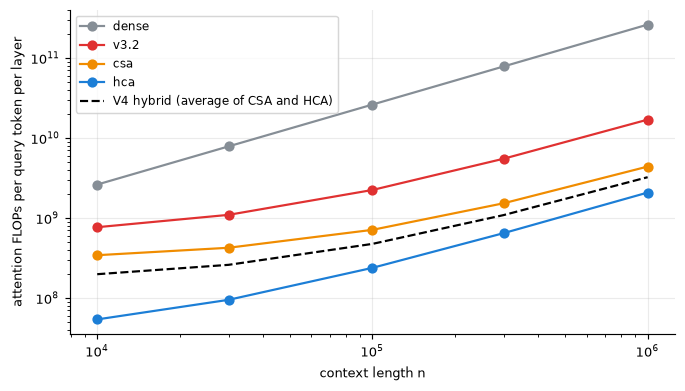

per query token per layer at n=1M:  dense    262.1 GF | V3.2-like  16.99 GF | CSA  4.40 GF (indexer 4.10 GF) | HCA  2.08 GF
summed over 61 layers:  V4-Pro attention 196 GF   V3.2-like attention 1036 GF   -> 0.19x of V3.2's attention FLOPs
adding 2 x activated params (Pro 49B, V3.2 37B): per-token total ratio V4-Pro / V3.2 at 1M = 0.27   (paper: 0.27, i.e. 3.7x lower)
PASS CSA's indexer, not its core attention, dominates CSA's cost at 1M tokens
PASS V4 attention FLOPs at 1M tokens are >50x below dense attention (our arithmetic)   [81x]
PASS our estimate of the V4-Pro / V3.2 per-token FLOP ratio at 1M is within 0.15 of the paper's 0.27 (assumed V3.2 config)   [0.27]


In [9]:
nh, c, nIh, cI, m, mp, k, nwin = 128, 512, 64, 128, 4, 128, 1024, 128
def f_attn(L, nh=nh, c=c): return 2 * 2 * nh * c * L
def flops(kind, n):
    if kind == "dense":  return f_attn(n)
    if kind == "v3.2":   return 2 * 2 * 128 * 576 * min(2048, n) + 2 * 64 * 128 * n                      # ASSUMED V3.2: MLA 128 heads x 576 dims, top-2048, indexer 64x128 over n entries
    if kind == "csa":    return f_attn(min(k, n // m) + nwin) + 2 * nIh * cI * (n // m)
    if kind == "hca":    return f_attn(n // mp + nwin)
ns = np.array([1e4, 3e4, 1e5, 3e5, 1e6]); fig, ax = plt.subplots(figsize=(6.6, 3.8))
for kind, col in [("dense", "#868e96"), ("v3.2", "#e03131"), ("csa", "#f08c00"), ("hca", "#1c7ed6")]: ax.loglog(ns, [flops(kind, int(x)) for x in ns], "o-", color=col, label=kind)
ax.loglog(ns, [(flops("csa", int(x)) + flops("hca", int(x))) / 2 for x in ns], "k--", label="V4 hybrid (average of CSA and HCA)")
ax.set_xlabel("context length n"); ax.set_ylabel("attention FLOPs per query token per layer"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
N = 1_000_000; layers = 61
v4_attn = (flops("csa", N) * 30 + flops("hca", N) * 31) * 1.0                                          # 61 layers: 30 CSA-like + 31 HCA-like (first two HCA)
v32_attn = flops("v3.2", N) * layers
print(f"per query token per layer at n=1M:  dense {flops('dense', N) / 1e9:8.1f} GF | V3.2-like {flops('v3.2', N) / 1e9:6.2f} GF | CSA {flops('csa', N) / 1e9:5.2f} GF (indexer {2 * nIh * cI * (N // m) / 1e9:.2f} GF) | HCA {flops('hca', N) / 1e9:5.2f} GF")
print(f"summed over 61 layers:  V4-Pro attention {v4_attn / 1e9:.0f} GF   V3.2-like attention {v32_attn / 1e9:.0f} GF   -> {v4_attn / v32_attn:.2f}x of V3.2's attention FLOPs")
rest_v4, rest_v32 = 2 * 49e9, 2 * 37e9
tot_ratio = (rest_v4 + v4_attn) / (rest_v32 + v32_attn)
print(f"adding 2 x activated params (Pro 49B, V3.2 37B): per-token total ratio V4-Pro / V3.2 at 1M = {tot_ratio:.2f}   (paper: 0.27, i.e. 3.7x lower)")
check("CSA's indexer, not its core attention, dominates CSA's cost at 1M tokens", 2 * nIh * cI * (N // m) > f_attn(min(k, N // m) + nwin))
check("V4 attention FLOPs at 1M tokens are >50x below dense attention (our arithmetic)", flops("dense", N) / ((flops("csa", N) + flops("hca", N)) / 2) > 50, f"{flops('dense', N) / ((flops('csa', N) + flops('hca', N)) / 2):.0f}x")
check("our estimate of the V4-Pro / V3.2 per-token FLOP ratio at 1M is within 0.15 of the paper's 0.27 (assumed V3.2 config)", abs(tot_ratio - 0.27) < 0.15, f"{tot_ratio:.2f}")

**What we found.** At a million tokens the **indexer**, not the attention it feeds, is the largest CSA cost (about 4.1 GFLOPs against 0.3 GFLOPs for the core attention per layer-token). That explains the report's choices to compress the indexer's keys by `m`, to run its attention in FP4 and to pick a smaller `k` than V3.2. HCA has no indexer, so it is cheaper per layer at 1M despite being dense. Our end-to-end estimate of the V4-Pro to V3.2 ratio comes out at 0.27, the same as the report's figure; but it rests on assumed V3.2 numbers and on ignoring everything but attention and the activated-parameter count, so we treat it as agreement within the slack of those assumptions, not as a reproduction. Against dense attention the hybrid is about 80× cheaper at 1M tokens by this count.

<p align="center"><img src="images/fig6_kv_layout.png" width="780"><br><sub>Fig. 6 (report): the inference KV layout. Notice the split into a fixed-size 'state cache' (sliding-window entries and the not-yet-compressible tail of each block) and a classical block cache for the compressed entries; the compressed blocks are sized so that one block covers lcm(m, m') = 128 original tokens.</sub></p>

## Closing thoughts

Compressing the KV cache is an old idea; what V4 does is combine two compression rates in one network (4× with selection, 128× without) and make every piece causal and cheap enough to train at 1T-parameter scale. Our checks confirm the mechanics: the compressors are causal and reduce the length by `m`, the indexer's top-`k` respects visibility, the output rotation makes the attention output position-relative, and the full layer is strictly causal; and our cache arithmetic reproduces the report's ~2 % of a GQA8 cache.

**What this notebook does not establish.** We did not train anything, so we say nothing about quality: whether `m = 4`, `k = 1024`, or the 128-token window are the right sizes, or what the grouped output projection costs. The report does not ablate them either in the sections we read. The V3.2 numbers in Section 8 are our assumptions. We also made four implementation choices the report leaves to its code (listed before the full layer).

**Next.** Notebook 2 covers the other architectural change that touches every layer, the manifold-constrained residual stream.

Credits: the method and all quoted results are from DeepSeek-AI's V4 technical report; the attention-sink idea is from Xiao et al., and RoPE from Su et al.

In [10]:
print(f"{'#':>2s}  {'status':6s}  check")
for i, (n_, ok, d_) in enumerate(CHECKS, 1): print(f"{i:2d}  {'PASS' if ok else 'FAIL':6s}  {n_}")
failed = [n_ for n_, ok, _ in CHECKS if not ok]; print(f"\n{len(CHECKS) - len(failed)} passed, {len(failed)} failed")
assert not failed, failed

 #  status  check
 1  PASS    V4-Pro KV cache is 1.5-3.5% of BF16 GQA8 at 1M tokens (paper: 'approximately 2%')
 2  PASS    worked example: HCA compression of [10,20,30,40] with logits [0,1,2,3] is 34.9
 3  PASS    vectorised CSA compressor equals a literal loop over Eqs. 11-12
 4  PASS    sequence length shrinks by m (not 2m) despite each entry using 2m tokens
 5  PASS    compressed entries 0..2 (built from tokens < 12) are untouched by changes to tokens >= 12
 6  PASS    HCA with m'=8 turns 24 tokens into 3 entries
 7  PASS    vectorised indexer scores equal the literal double loop over Eq. 16
 8  PASS    every selected block is entirely in the past (s < floor(t/m)) and early tokens select min(k, floor(t/m)) blocks
 9  PASS    top-k equals a brute-force sort over visible blocks for all 40 query tokens
10  PASS    sink attention equals softmax over [logits, sink] with a zero-valued extra entry
11  PASS    with a sink the attention weights sum to < 1; with sink = -50 they sum to 1
12  